In [1]:
import numpy as np
from hcipy import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [18]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

In [3]:
from scipy import ndimage

def hpf(data,sigma):
    return Field((data.shaped - ndimage.gaussian_filter(data.shaped,sigma)).ravel(),data.grid)

In [4]:
#fitting functions
from scipy.optimize import curve_fit

def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    new_data = data.copy()

    mid = np.argmax(new_data)
    first_derivative = np.gradient(new_data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        new_data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        new_data[right_valley:len(new_data)] = 0
        #print(right_valley)

    return new_data


def mu(data):
    isolated = isolate_gaussian(data)
    x = np.arange(len(data))
    popt = curve_fit(gauss,x,isolated,p0=[np.argmax(data),2])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return mu, sigma, fwhm
    

(262144,)

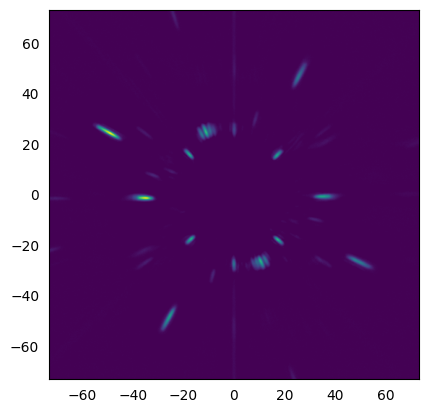

In [5]:
#img = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_unsat.fits')[0]
img = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')[25]
img = hpf(img,20)
img = ADC.crop_image(img,extent=512,mask_diam=20)


#img = img_cube[3]
fig, ax = plt.subplots()
imshow_field(img)
ax.tick_params(left=False,right=False,bottom=False)
img.shape

[-54.73780488   0.        ]


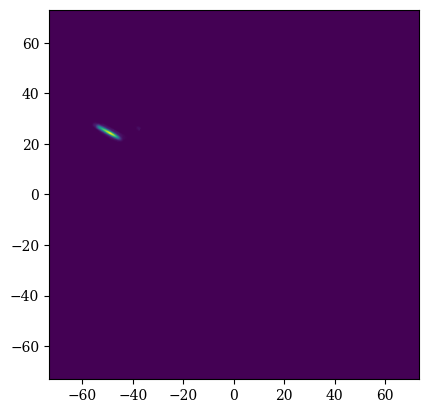

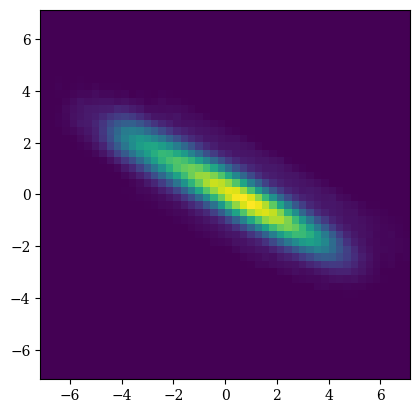

In [21]:
#cut out the speckle window
speckle_number = 3

#locate the general area of the speckle
extent=20
speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
speckle_center = speckle_coords[speckle_number]
print(speckle_center)

#cut out the speckle area
rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
speckle_img = rect * img

#find the center of intensity of the speckle area and window the image around that center
center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
window_size=50
new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

#tada!
imshow_field(speckle_img)
plt.figure()
imshow_field(new_img)

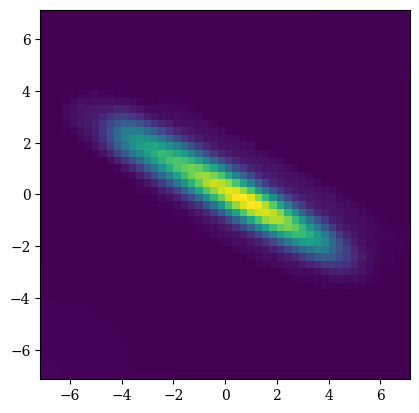

In [22]:
#and now filter it!
hp_sigma = 20
lp_sigma = 0
hp = hpf(new_img,hp_sigma)
lp = hp - hpf(hp,lp_sigma)
lp -= np.median(lp)
lp[lp < 0 ] = 0
new_img = lp
imshow_field(new_img)

In [23]:
#now iterate through all the slices
shaped = new_img.shaped
mus = np.zeros(shaped.shape[0])
zscores = np.zeros(shaped.shape[0])
maxes = np.zeros(shaped.shape[0])

snr_threshold = 1.6


for i in range(shaped.shape[0]): #in np.array([40,0]):
    if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
        sliced = shaped[:,i]
    else: sliced = shaped[i,:]

    zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)
    zscores[i] = zscore

    if zscore > snr_threshold:
        s = isolate_gaussian(sliced)
        s /= s.max()
        m, std, fwhm = mu(s)
        mus[i] = m
    else: mus[i] = -1


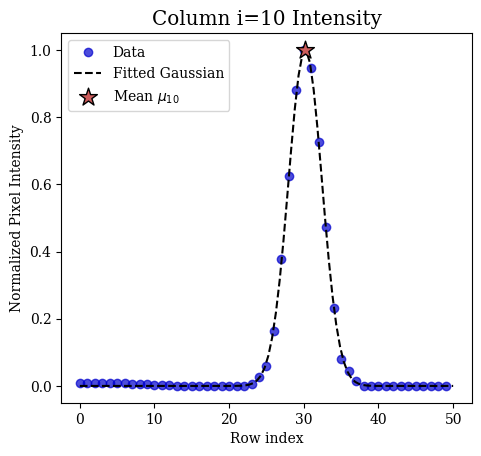

In [93]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.titlesize'] = 'x-large'
sliced = shaped[:,15]

s = isolate_gaussian(sliced)
s /= s.max()

mean, sd, width = mu(s)

gauss_x = np.linspace(0,50,100)

x = np.arange(40)
fig,axs = plt.subplots()
plt.plot(s,'o',label='Data',color='mediumblue',alpha=0.7)
plt.plot(gauss_x,gauss(gauss_x,mean,sd),'--',label='Fitted Gaussian',color='black')
plt.scatter(mean,1,s=180,marker='*',color='indianred',label=r'Mean $\mu_{10}$',edgecolors='black',alpha=1,zorder=11)
plt.xlabel('Row index')
plt.ylabel('Normalized Pixel Intensity')
plt.title('Column i=10 Intensity')

axs.set_box_aspect(0.9)
plt.legend()
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/column_gaussian.png',dpi=300)

#plt.plot(x,s - gauss(x,mean,sd),'o',label='Residuals')
# plt.vlines(mean - width/2,0,1,'gray',label='FWHM bounds')
# plt.vlines(mean + width/2,0,1,'gray')
plt.show()

In [70]:
mean

np.float64(30.18959190080586)

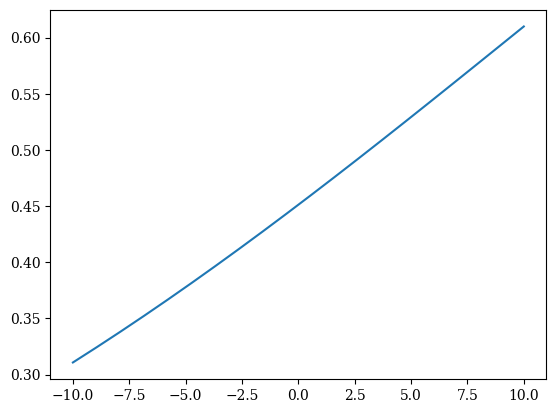

In [24]:
x = np.linspace(-10,10,20)
g = gauss(x,m,std**2)
plt.plot(x,g)

Text(0, 0.5, 'row index of mean position')

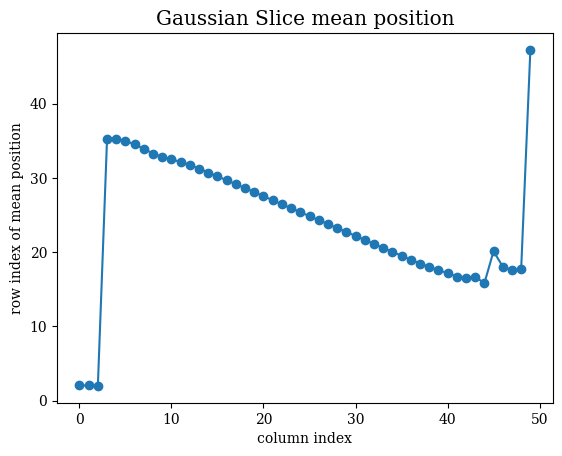

In [25]:
#plot the means
plt.plot(mus,'-o')
plt.title('Gaussian Slice mean position')
plt.xlabel('column index')
plt.ylabel('row index of mean position')

[ 0  1  2  3  4  5  6  8  9 11 12 13 37 38 40 41 43 44 45 46 47 48 49]
slope: -0.53
corresponding angle: -0.49 (rad) or -28.14°


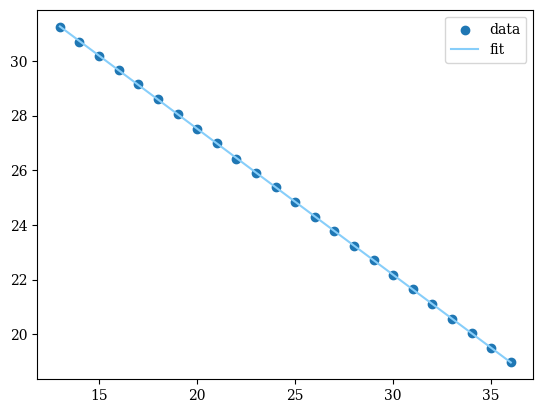

In [26]:
#plot the linear region
deriv2 = np.gradient(np.gradient(mus))

deriv2_cutoff = 0.018

nonlin_region = np.squeeze(np.where(np.abs(deriv2) > deriv2_cutoff))
print(nonlin_region)

midpoint = 20
# leftbound = nonlin_region[nonlin_region < midpoint][-1]
# rightbound = nonlin_region[nonlin_region > midpoint][0]

if any(nonlin_region < midpoint):
    leftbound = nonlin_region[nonlin_region < midpoint][-1]
elif deriv2[0] <= 0.4:
    leftbound = 0
    print('speckle falls off left (bottom) edge')
else: leftbound = None

if any(nonlin_region > midpoint):
    rightbound = nonlin_region[nonlin_region > midpoint][0]
elif deriv2[-1] <= 0.4:
    rightbound = 50
    print('speckle falls off right (top) edge')
else: rightbound = None

linear_region = mus[leftbound:rightbound]
lin_x = np.arange(len(linear_region)) + leftbound

m , b = np.polyfit(lin_x,linear_region,deg=1)

if speckle_number %2 ==0:
        angle = np.arctan(1/m)
else: angle = np.arctan(m)
print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')
plt.scatter(lin_x,linear_region,label='data')
plt.plot(lin_x, m * lin_x + b,label='fit',color='LightSkyBlue')
plt.legend()
plt.show()

In [105]:
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

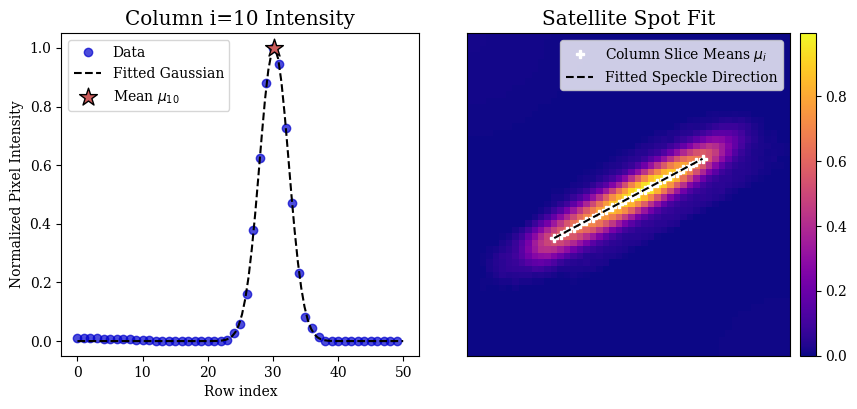

In [125]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.titlesize'] = 'x-large'
sliced = shaped[:,15]

s = isolate_gaussian(sliced)
s /= s.max()

mean, sd, width = mu(s)

gauss_x = np.linspace(0,50,100)
x = np.arange(40)

fig,axs = plt.subplots(1,2,figsize=(9,4))
axs[0].plot(s,'o',label='Data',color='mediumblue',alpha=0.7)
axs[0].plot(gauss_x,gauss(gauss_x,mean,sd),'--',label='Fitted Gaussian',color='black')
axs[0].scatter(mean,1,s=180,marker='*',color='indianred',label=r'Mean $\mu_{10}$',edgecolors='black',alpha=1,zorder=11)
axs[0].set_xlabel('Row index')
axs[0].set_ylabel('Normalized Pixel Intensity')
axs[0].set_title('Column i=10 Intensity')

axs[0].set_box_aspect(0.9)
axs[0].legend()
# axs[0].plot(x,s - gauss(x,mean,sd),'o',label='Residuals')
# axs[0].vlines(mean - width/2,0,1,'gray',label='FWHM bounds')
# axs[0].vlines(mean + width/2,0,1,'gray')

im = axs[1].imshow(new_img.shaped,origin='upper',cmap='plasma')
#imshow_field(new_img)
if speckle_number %2 == 0:
    axs[1].plot(mus[leftbound:rightbound], lin_x,'o',color='white',marker='.')
else: axs[1].plot(lin_x ,mus[leftbound:rightbound],color='white',label=r'Column Slice Means $\mu_i$',marker='P',linestyle='')
axs[1].plot(lin_x, m * lin_x + b,'--',color='black',label='Fitted Speckle Direction',linewidth=1.5)
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].legend()
axs[1].set_title('Satellite Spot Fit')
colorbar(im)

fig.tight_layout(h_pad=1)

# c = axs[1].set_colorbar()
# c.set_label('Intensity')

#fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/lyot/single_speckle.png',dpi=300)
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/fitting_demo.png',dpi=300)

In [13]:
#ok let's try this again idk what changed
def slice_speckle_angle(img,speckle_number,print_updates=False):
    extent=20
    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    print(speckle_center)

    #cut out the speckle area
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
    speckle_img = rect * img

    #find the center of intensity of the speckle area and window the image around that center
    center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
    window_size=50
    new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

    #and now filter it!
    hp_sigma = 10
    lp_sigma = 5
    hp = hpf(new_img,hp_sigma)
    lp = hp - hpf(hp,lp_sigma)
    lp -= np.median(lp)
    lp[lp < 0 ] = 0
    new_img = lp
    
    shaped = new_img.shaped
    mus = np.zeros(shaped.shape[0])

    snr_threshold = 1.6

    for i in range(shaped.shape[0]): #in np.array([40,0]):
        if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
            sliced = shaped[:,i]
        else: sliced = shaped[i,:]

        zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)

        if zscore > snr_threshold:
            s = isolate_gaussian(sliced)
            s /= s.max()
            m, std, fwhm = mu(s)
            mus[i] = m
        else: mus[i] = -1

    deriv2 = np.gradient(np.gradient(mus))
    nonlin_region = np.squeeze(np.where(np.abs(deriv2) > 0.4))
    #print(nonlin_region)

    midpoint = 20
    
    if any(nonlin_region < midpoint):
        leftbound = nonlin_region[nonlin_region < midpoint][-1]
    elif deriv2[0] <= 0.4:
        leftbound = 0
        #print('speckle falls off left (bottom) edge')
    else: leftbound = None

    if any(nonlin_region > midpoint):
        rightbound = nonlin_region[nonlin_region > midpoint][0]
    elif deriv2[-1] <= 0.4:
        rightbound = 50
        #print('speckle falls off right (top) edge')
    else: rightbound = None

    if leftbound is not None and rightbound is not None:
        linear_region = mus[leftbound:rightbound]
        lin_x = np.arange(len(linear_region))

        m , b = np.polyfit(lin_x,linear_region,deg=1)
        if speckle_number %2 ==0:
            angle = np.arctan(1/m)
        else: angle = np.arctan(m)
        if print_updates ==True:
            print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')

        return np.degrees(angle)
    else: 
        if print_updates == True:
            print(f'unable to fit speckle {speckle_number}')
        return np.nan


In [14]:
slice_speckle_angle(img,2)

[  0.        -32.6097561]


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_18972/752453967.py:36: RuntimeWarning: invalid value encountered in divide
  zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)
/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_18972/3528794934.py:5: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


np.float64(-87.03328167391581)

In [15]:
#now find the speckle angles for all four 
def all_speckle_angles(img):
    angles = np.zeros(4)
    for i in range(4):
        #print(i)
        angles[i] = slice_speckle_angle(img,i)
    return angles

In [16]:
a = all_speckle_angles(img)

[ 0.        32.6097561]


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_18972/752453967.py:36: RuntimeWarning: invalid value encountered in divide
  zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)


[32.6097561  0.       ]
[  0.        -32.6097561]
[-32.6097561   0.       ]


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_18972/3528794934.py:5: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


In [17]:
a

array([ 87.44248563,   0.18971161, -87.03328167,  -2.07654547])